In [16]:
import os

print(os.listdir(r"C:\Users\DELL\Desktop\Uber_Analytics_Project\data"))

['cleaned_uber_data.csv', 'uber.csv']


In [17]:
import os

print(os.path.isfile(r"C:\Users\DELL\Desktop\Uber_Analytics_Project\data\uber.csv"))
print(os.path.isdir(r"C:\Users\DELL\Desktop\Uber_Analytics_Project\data\uber.csv"))

True
False


In [18]:
import pandas as pd

df = pd.read_csv(r"C:\Users\DELL\Desktop\Uber_Analytics_Project\data\uber.csv")

print("Dataset Loaded Successfully")
print(df.shape)
print(df.head())
print(df.columns.tolist())

Dataset Loaded Successfully
(200000, 9)
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565        

In [19]:
import os

print(os.getcwd())


c:\Users\DELL\Desktop\Uber_Analytics_Project\noteboks


UBER DATA ANALYTICS PROJECT

Dataset Loaded Successfully!

Dataset Shape:
(200000, 9)

Column Names:
['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count']

First 5 Rows:
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73

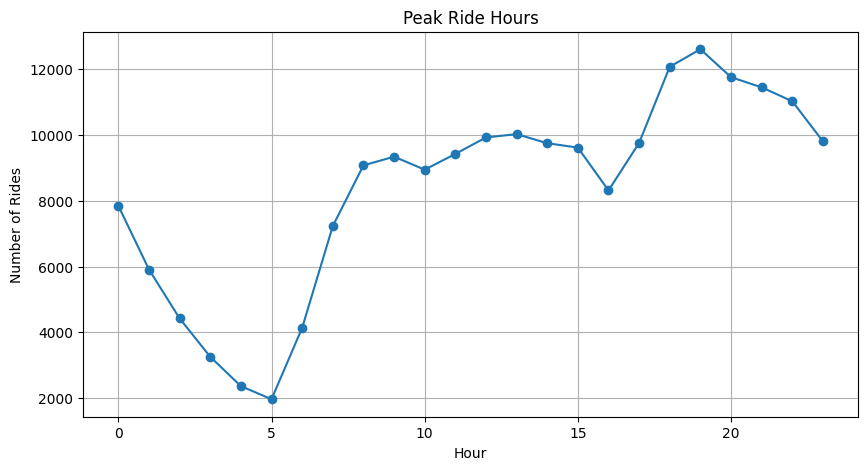

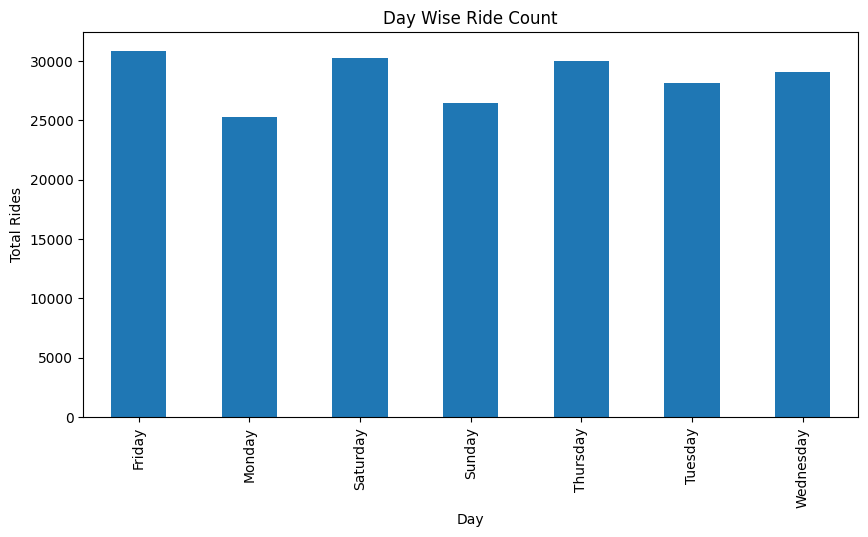

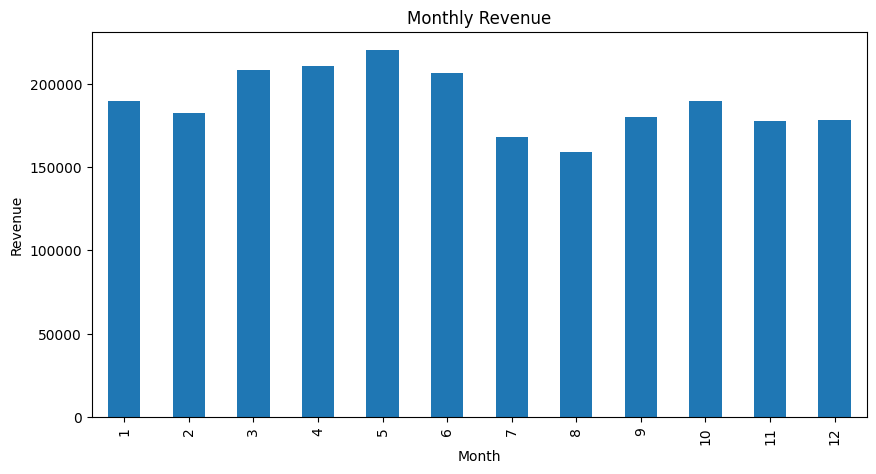

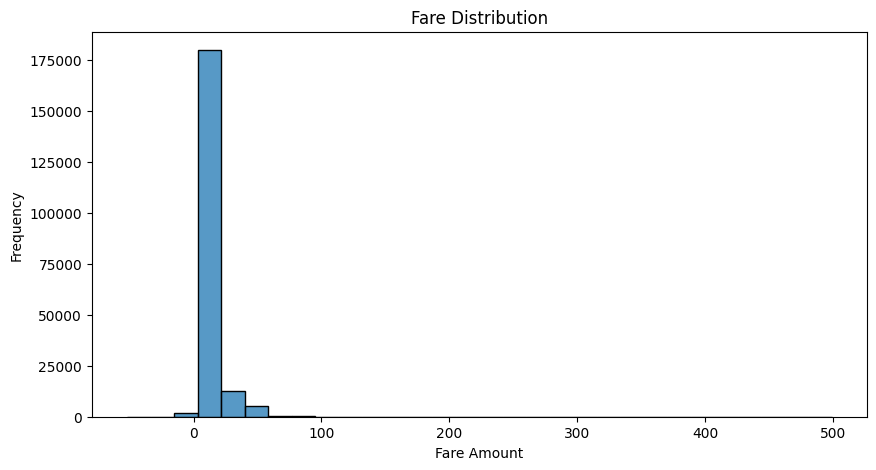

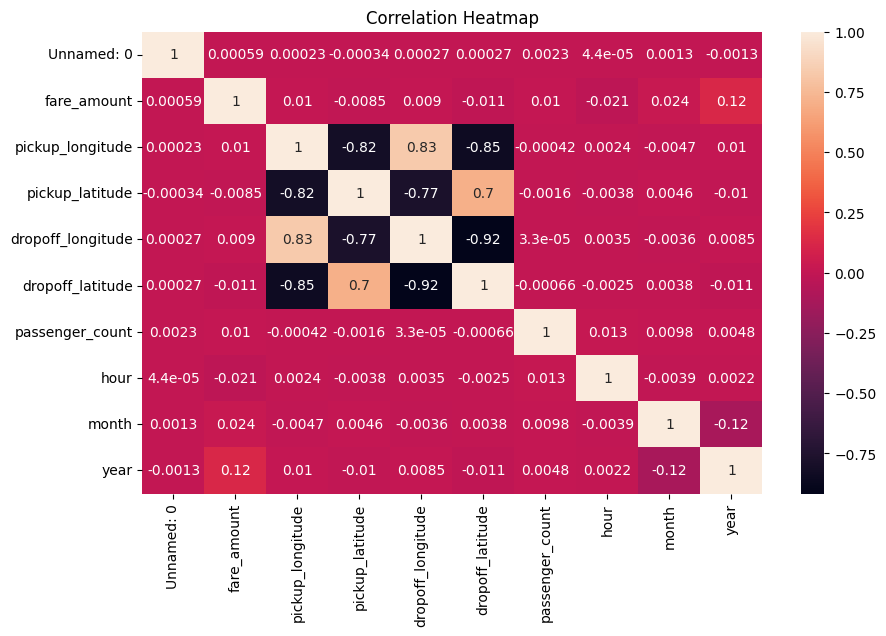


Top Ride Hours
hour
19    12605
18    12072
20    11755
21    11446
22    11023
dtype: int64

MACHINE LEARNING
Mean Absolute Error : 6.06
R2 Score : 0.0

Sample Predictions
   Actual Fare  Predicted Fare
0          6.5       11.455166
1          4.1       11.285320
2         12.0       10.877283
3          7.5       11.030820
4          4.1       11.714655
5         12.0       11.698614
6         14.5       11.073416
7          6.5       11.751725
8          8.9       11.953115
9          7.7       10.887798

Cleaned dataset saved successfully!

Final Dataset Shape:
(199999, 13)

PROJECT COMPLETED SUCCESSFULLY
cleaned_uber_data.csv CREATED


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# ===================================
# UBER DATA ANALYTICS PROJECT
# ===================================

print("===================================")
print("UBER DATA ANALYTICS PROJECT")
print("===================================\n")

# ===================================
# LOAD DATASET
# ===================================

df = pd.read_csv("../data/uber.csv")

print("Dataset Loaded Successfully!\n")

# ===================================
# DATA OVERVIEW
# ===================================

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Info:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

# ===================================
# DATA CLEANING
# ===================================

print("\nMissing Values:")
print(df.isnull().sum())

df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

print("\nDataset Shape After Cleaning:")
print(df.shape)

# ===================================
# DATE CONVERSION
# ===================================

df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

# ===================================
# FEATURE ENGINEERING
# ===================================

df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day_name()
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year

# ===================================
# BASIC ANALYSIS
# ===================================

print("\n==========================")
print("BASIC ANALYSIS")
print("==========================")

print("Total Rides :", len(df))
print("Average Fare :", round(df['fare_amount'].mean(), 2))
print("Maximum Fare :", round(df['fare_amount'].max(), 2))
print("Minimum Fare :", round(df['fare_amount'].min(), 2))

# ===================================
# PEAK HOUR ANALYSIS
# ===================================

hourly_rides = df.groupby('hour').size()

plt.figure(figsize=(10,5))
hourly_rides.plot(marker='o')
plt.title("Peak Ride Hours")
plt.xlabel("Hour")
plt.ylabel("Number of Rides")
plt.grid(True)
plt.show()

# ===================================
# DAY WISE ANALYSIS
# ===================================

rides_by_day = df.groupby('day').size()

plt.figure(figsize=(10,5))
rides_by_day.plot(kind='bar')
plt.title("Day Wise Ride Count")
plt.xlabel("Day")
plt.ylabel("Total Rides")
plt.show()

# ===================================
# MONTHLY REVENUE ANALYSIS
# ===================================

monthly_revenue = df.groupby('month')['fare_amount'].sum()

plt.figure(figsize=(10,5))
monthly_revenue.plot(kind='bar')
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

# ===================================
# FARE DISTRIBUTION
# ===================================

plt.figure(figsize=(10,5))
sns.histplot(df['fare_amount'], bins=30)

plt.title("Fare Distribution")
plt.xlabel("Fare Amount")
plt.ylabel("Frequency")

plt.show()

# ===================================
# CORRELATION HEATMAP
# ===================================

plt.figure(figsize=(10,6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True
)

plt.title("Correlation Heatmap")

plt.show()

# ===================================
# TOP HOURS TABLE
# ===================================

print("\nTop Ride Hours")

top_hours = df.groupby('hour').size().sort_values(ascending=False)

print(top_hours.head())

# ===================================
# MACHINE LEARNING
# ===================================

print("\n==========================")
print("MACHINE LEARNING")
print("==========================")

X = df[['hour', 'month']]
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

model = LinearRegression()

model.fit(X_train, y_train)

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("Mean Absolute Error :", round(mae, 2))
print("R2 Score :", round(r2, 2))

comparison = pd.DataFrame({
    "Actual Fare": y_test.values[:10],
    "Predicted Fare": predictions[:10]
})

print("\nSample Predictions")
print(comparison)

# ===================================
# SAVE CLEANED DATA
# ===================================

df.to_csv(
    "../data/cleaned_uber_data.csv",
    index=False
)

print("\nCleaned dataset saved successfully!")

print("\nFinal Dataset Shape:")
print(df.shape)

print("\n===================================")
print("PROJECT COMPLETED SUCCESSFULLY")
print("cleaned_uber_data.csv CREATED")
print("===================================")

In [21]:
import sqlite3
import pandas as pd

df = pd.read_csv(r"C:\Users\DELL\Desktop\Uber_Analytics_Project\data\cleaned_uber_data.csv")

conn = sqlite3.connect(r"C:\Users\DELL\Desktop\Uber_Analytics_Project\sql\uber.db")

df.to_sql("rides", conn, if_exists="replace", index=False)

print("Database Created Successfully")

conn.close()

Database Created Successfully


In [22]:
import sqlite3
import pandas as pd

conn = sqlite3.connect(r"C:\Users\DELL\Desktop\Uber_Analytics_Project\sql\uber.db")

query = """
SELECT COUNT(*) AS total_rides
FROM rides;
"""

result = pd.read_sql_query(query, conn)

print(result)

conn.close()

   total_rides
0       199999


In [23]:
import sqlite3
import pandas as pd

conn = sqlite3.connect(r"C:\Users\DELL\Desktop\Uber_Analytics_Project\sql\uber.db")

queries = {
    "Total Rides": "SELECT COUNT(*) AS total_rides FROM rides",
    "Average Fare": "SELECT AVG(fare_amount) AS average_fare FROM rides",
    "Maximum Fare": "SELECT MAX(fare_amount) AS max_fare FROM rides",
    "Minimum Fare": "SELECT MIN(fare_amount) AS min_fare FROM rides",
    "Total Revenue": "SELECT SUM(fare_amount) AS total_revenue FROM rides"
}

for title, query in queries.items():
    print(f"\n===== {title} =====")
    print(pd.read_sql_query(query, conn))

conn.close()


===== Total Rides =====
   total_rides
0       199999

===== Average Fare =====
   average_fare
0     11.359892

===== Maximum Fare =====
   max_fare
0     499.0

===== Minimum Fare =====
   min_fare
0     -52.0

===== Total Revenue =====
   total_revenue
0     2271966.95
